# Meeting 1 — Dataset protocol and real-data baselines

**Research question:** can diffusion-generated images improve recognition of an underrepresented class
(Egyptian Mau) beyond oversampling and ordinary augmentation, without harming overall classification quality?

This notebook only *calls* code from `src/catbench/` and shows the results. The full protocol is in
[`protocol.md`](protocol.md). The first run downloads Oxford-IIIT Pet (~800 MB) into `data/`; later runs use cached files.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from catbench import config
from catbench.split import get_manifest, class_count_table
from catbench.leakage import check_split
from catbench.features import augmented_images
from catbench.data import load_image
from catbench.train_eval import run_baselines, summarize
from catbench import plots

pd.set_option("display.width", 160)
print("PyTorch", torch.__version__, "| device:", "cuda" if torch.cuda.is_available() else "cpu")

D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.11.0+cu128 | device: cuda


## 1. Split the real images once → manifest

Every cat image gets exactly one role: `train`, `val`, `test`, `unused` (Egyptian Mau images left out to create the
imbalance) or `excluded_duplicate` (near-duplicate photos removed *before* splitting).
The manifest is created once with `SPLIT_SEED` and saved to `manifests/split_manifest.csv`, which is committed to Git —
on another computer the same file is loaded, so the split is identical.

In [2]:
manifest = get_manifest()
manifest.head()

,image_id,breed,role,official_split,duplicate_of,dhash,path
0,Abyssinian_1,Abyssinian,unused,trainval,,f0f8f8883ef0f0e8,oxford-iiit-pet/images/Abyssinian_1.jpg
1,Abyssinian_10,Abyssinian,train,trainval,,e3c1c9c0c2800606,oxford-iiit-pet/images/Abyssinian_10.jpg
2,Abyssinian_100,Abyssinian,unused,trainval,,cf0f1f3ffffcf9f3,oxford-iiit-pet/images/Abyssinian_100.jpg
3,Abyssinian_101,Abyssinian,train,trainval,,465e493931130c0c,oxford-iiit-pet/images/Abyssinian_101.jpg
4,Abyssinian_102,Abyssinian,unused,trainval,,373392e3d262e0b0,oxford-iiit-pet/images/Abyssinian_102.jpg


In [3]:
class_count_table(manifest)

role,train,val,test,unused,excluded_duplicate
breed,,,,,
Abyssinian,70,20,30,72,6
Bengal,70,20,30,80,0
Birman,70,20,30,79,1
Bombay,70,20,30,56,8
Egyptian Mau,15,20,30,123,2
Ragdoll,70,20,30,79,1
Russian Blue,70,20,30,80,0
Siamese,70,20,30,79,0
Total,505,160,240,648,18


## 2. Automated leakage check

The check raises an error if anything fails. It verifies unique IDs, the protocol's class counts and that no near-duplicate
photo (perceptual dHash) crosses train/val/test. A separate check runs every time an oversampled or augmented training set
is built: each added observation must come from an Egyptian Mau **training** image.

In [4]:
check_split(manifest)

,check,passed,detail
0,image IDs unique (one role per image),True,
1,only known roles,True,
2,train counts (70 majority / 15 minority),True,
3,validation balanced (20 per class),True,
4,test balanced (30 per class),True,
5,no near-duplicates across splits (dHash <= 6 b...,True,


18 near-duplicate images excluded before splitting


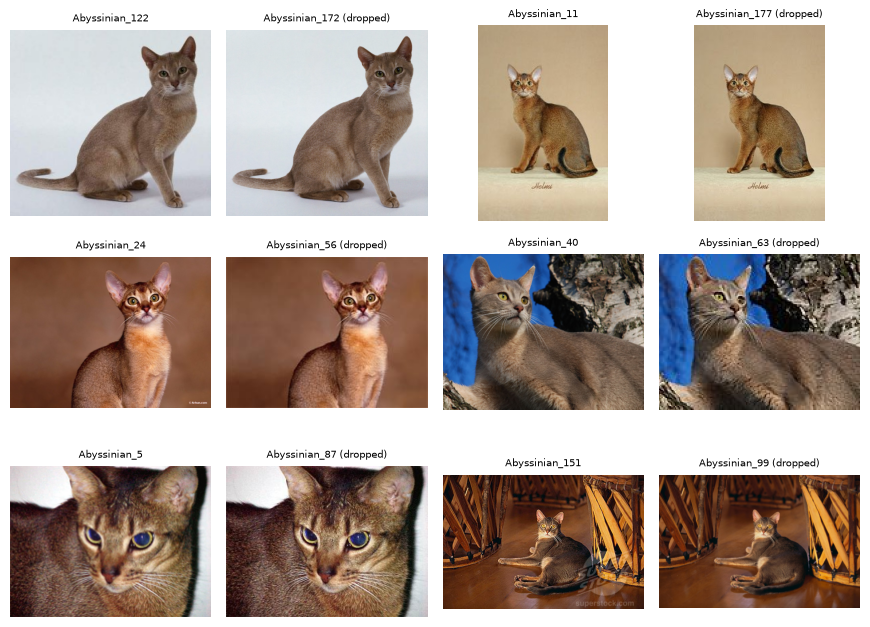

In [5]:
dups = manifest[manifest.role == "excluded_duplicate"]
print(f"{len(dups)} near-duplicate images excluded before splitting")
pairs = dups.head(6)
paths = dict(zip(manifest.image_id, manifest.path))
imgs, titles = [], []
for r in pairs.itertuples():
    imgs += [load_image(paths[r.duplicate_of]), load_image(r.path)]
    titles += [r.duplicate_of, f"{r.image_id} (dropped)"]
if imgs:
    plots.image_grid(imgs, titles, ncols=4, size=2.2);

## 3. The minority class and the added-data budget

Egyptian Mau has only **15** training images, the other breeds **70**. Every added-data condition adds exactly
**55 = 70 − 15** minority observations: oversampling repeats the 15 images, and augmentation adds 55 transformed copies.

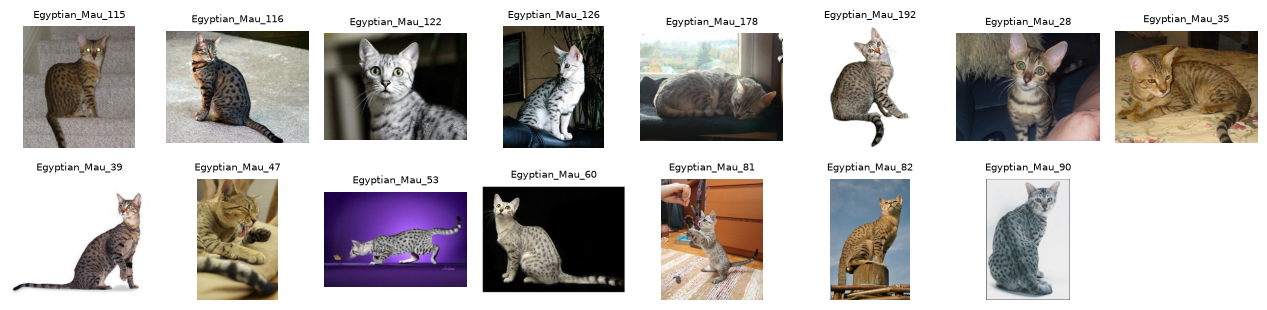

In [6]:
mau_train = manifest[(manifest.role == "train") & (manifest.breed == config.MINORITY)]
plots.image_grid([load_image(p) for p in mau_train.path], list(mau_train.image_id), ncols=8);

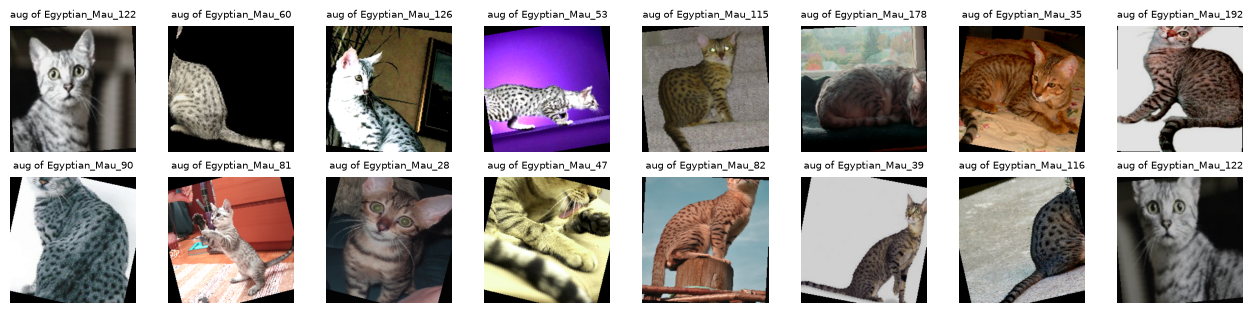

In [7]:
aug = augmented_images(manifest, seed=0)[:16]
plots.image_grid([img for _, img in aug], [f"aug of {s}" for s, _ in aug], ncols=8);

## 4. Three baselines

Frozen ImageNet backbone (ResNet-18, and EfficientNet-B0 as a check) → logistic regression.
The regularisation strength `C` is chosen on the **validation** set (macro-F1) for every condition and seed.
Each condition is run with 5 seeds (the seed changes which images are repeated and how they are augmented).
Test-set numbers are reported but never used for any choice.

In [8]:
runs, confusion = run_baselines(manifest, config.BACKBONES, config.CONDITIONS, config.RUN_SEEDS)
out = config.RESULTS_DIR / "meeting1"
out.mkdir(parents=True, exist_ok=True)
runs.to_csv(out / "runs.csv", index=False)
runs.head()

resnet18 real:   0%|          | 0/905 [00:00<?, ?it/s]

resnet18 real:   5%|▍         | 43/905 [00:00<00:02, 383.89it/s]

resnet18 real:  11%|█         | 96/905 [00:00<00:01, 463.90it/s]

resnet18 real:  16%|█▌        | 143/905 [00:00<00:01, 460.36it/s]

resnet18 real:  23%|██▎       | 210/905 [00:00<00:01, 540.89it/s]

...

efficientnet_b0 real:  88%|████████▊ | 795/905 [00:01<00:00, 500.15it/s]

efficientnet_b0 real:  94%|█████████▎| 847/905 [00:01<00:00, 503.48it/s]

efficientnet_b0 real:  99%|█████████▉| 900/905 [00:01<00:00, 509.39it/s]

efficientnet_b0 real: 100%|██████████| 905/905 [00:01<00:00, 504.93it/s]

,backbone,condition,seed,split,C,n_train,mau_recall,mau_precision,mau_f1,macro_f1,accuracy
0,resnet18,imbalanced,0,val,0.1,505,0.600000,1.000000,0.75000,0.867842,0.868750
1,resnet18,imbalanced,0,test,0.1,505,0.366667,0.916667,0.52381,0.844293,0.854167
2,resnet18,imbalanced,1,val,0.1,505,0.600000,1.000000,0.75000,0.867842,0.868750
3,resnet18,imbalanced,1,test,0.1,505,0.366667,0.916667,0.52381,0.844293,0.854167
4,resnet18,imbalanced,2,val,0.1,505,0.600000,1.000000,0.75000,0.867842,0.868750


### Validation set (used for model choices)

In [9]:
summarize(runs, "val")

mau_recall  mau_precision         mau_f1       macro_f1       accuracy
backbone        condition                                                                              
resnet18        imbalanced    0.600 ± 0.000  1.000 ± 0.000  0.750 ± 0.000  0.868 ± 0.000  0.869 ± 0.000
                oversampling  0.650 ± 0.000  0.918 ± 0.055  0.761 ± 0.019  0.869 ± 0.000  0.869 ± 0.000
                augmentation  0.650 ± 0.000  1.000 ± 0.000  0.788 ± 0.000  0.880 ± 0.000  0.881 ± 0.000
efficientnet_b0 imbalanced    0.650 ± 0.000  1.000 ± 0.000  0.788 ± 0.000  0.904 ± 0.000  0.906 ± 0.000
                oversampling  0.800 ± 0.000  0.941 ± 0.000  0.865 ± 0.000  0.918 ± 0.001  0.919 ± 0.000
                augmentation  0.820 ± 0.045  0.988 ± 0.026  0.896 ± 0.032  0.932 ± 0.007  0.932 ± 0.007

### Test set (locked — reported only)

In [10]:
summarize(runs, "test")

mau_recall  mau_precision         mau_f1       macro_f1       accuracy
backbone        condition                                                                              
resnet18        imbalanced    0.367 ± 0.000  0.917 ± 0.000  0.524 ± 0.000  0.844 ± 0.000  0.854 ± 0.000
                oversampling  0.580 ± 0.045  0.945 ± 0.004  0.718 ± 0.036  0.877 ± 0.006  0.880 ± 0.005
                augmentation  0.473 ± 0.015  0.934 ± 0.002  0.628 ± 0.013  0.857 ± 0.004  0.863 ± 0.004
efficientnet_b0 imbalanced    0.567 ± 0.000  0.944 ± 0.000  0.708 ± 0.000  0.862 ± 0.000  0.863 ± 0.000
                oversampling  0.653 ± 0.030  0.876 ± 0.014  0.748 ± 0.016  0.863 ± 0.000  0.863 ± 0.000
                augmentation  0.620 ± 0.018  0.912 ± 0.021  0.738 ± 0.018  0.866 ± 0.004  0.866 ± 0.003

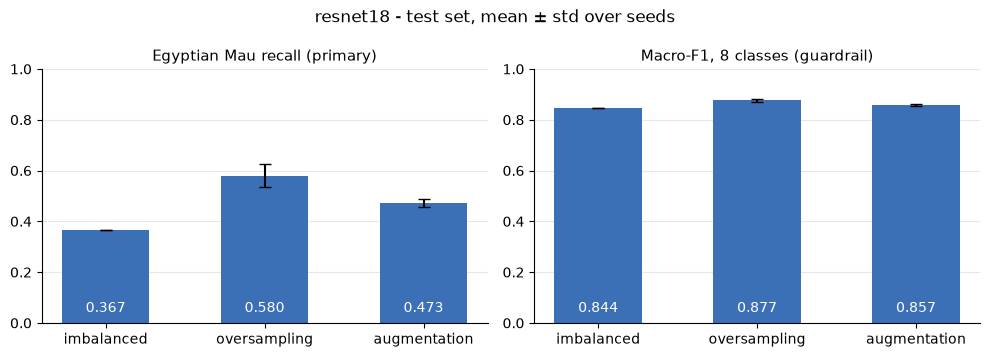

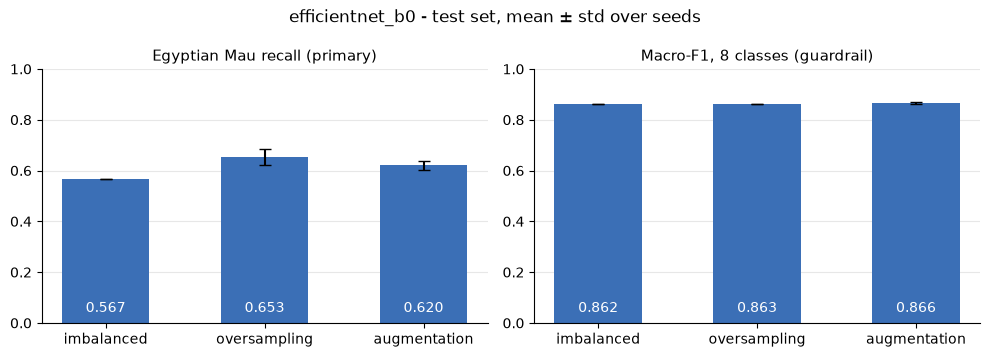

In [11]:
for bb in config.BACKBONES:
    plots.metric_bars(runs, bb, "test")
    plt.show()

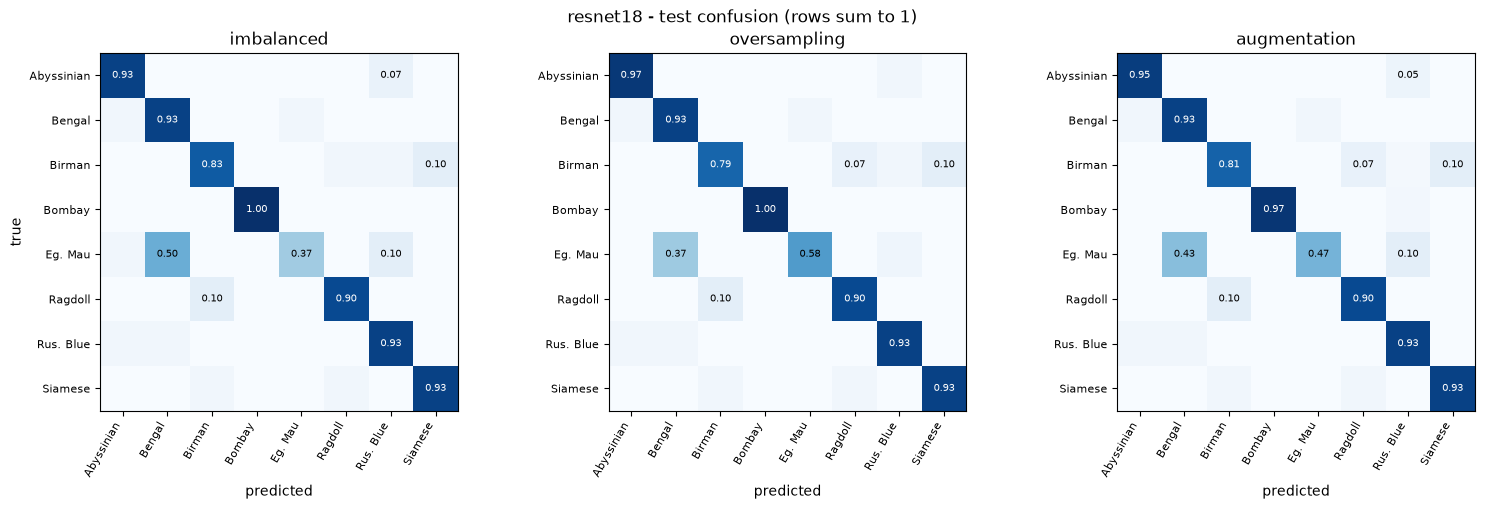

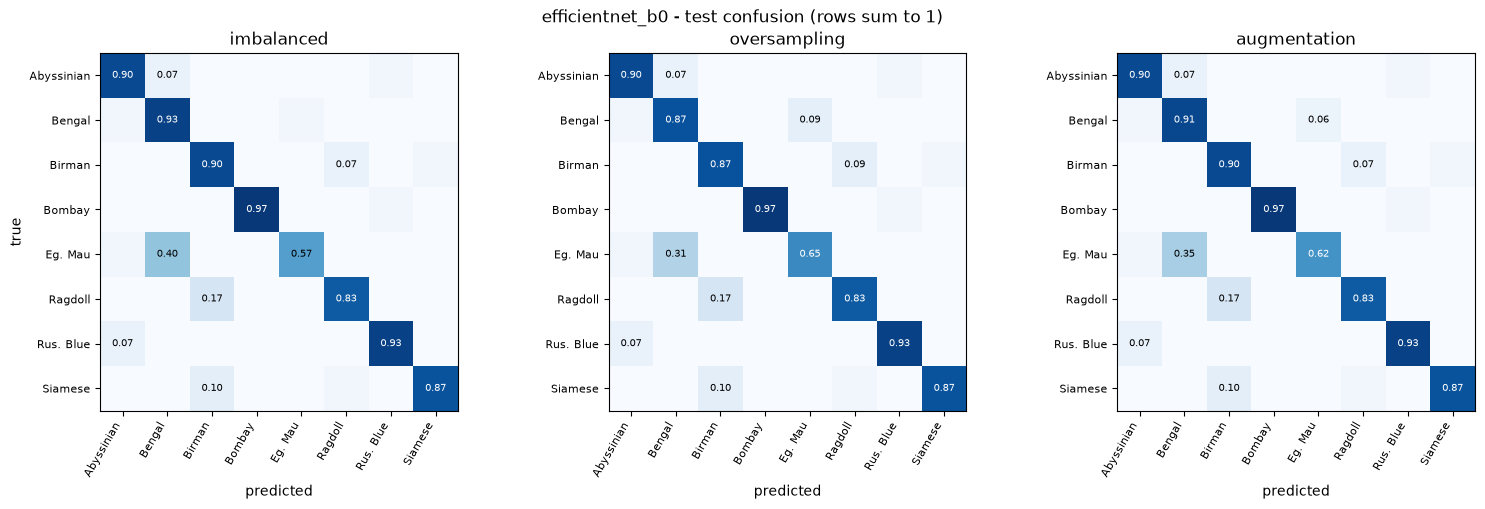

In [12]:
for bb in config.BACKBONES:
    plots.confusion_grid(confusion, bb, config.CONDITIONS)
    plt.show()

## 5. Takeaways

See the *Results* section of [`protocol.md`](protocol.md) for the interpretation of these numbers.